# 01 – Data Acquisition

## 1. Goal
Download all raw data automatically and prepare it for the two control municipalities Uznach (SG) and Pully (VD):
municipality boundaries, roof surfaces from sonnendach.ch, the BFE register of PV plants (reference data)
and SWISSIMAGE 10 cm aerial images.

> **Note on AI assistance:** Getting the raw data was relatively complicated. The datasets come from different
> portals (swisstopo, BFE / opendata.swiss) in different formats, some archives can't be unpacked with Python's
> `zipfile` (Deflate64 compression), the GeoPackage version of the BFE register is incomplete (cut off at
> 100'000 rows, so we use the CSV) and the SWISSIMAGE tiles have to be found via their file naming scheme.
> For this notebook we therefore used help from an AI assistant (Claude) to find the correct download links
> and write the download code. All later notebooks are written by ourselves.

## 2. Inputs / Outputs
| | |
| --- | --- |
| **Inputs** | Download links of swisstopo and BFE (see below) |
| **Outputs (raw)** | `data/raw/swissBOUNDARIES3D_1_5_LV95_LN02.gpkg`, `data/raw/SOLKAT_DACH.gpkg`, `data/raw/ElectricityProductionPlant.csv`, `data/raw/swissimage_uznach/*.tif`, `data/raw/swissimage_pully/*.tif` |
| **Outputs (interim)** | `data/interim/roofs_uznach.gpkg`, `data/interim/roofs_pully.gpkg`, `data/interim/pv_register_uznach.gpkg`, `data/interim/pv_register_pully.gpkg` |

**Sources**
- swissBOUNDARIES3D (swisstopo): https://www.swisstopo.admin.ch/de/landschaftsmodell-swissboundaries3d
- Solar suitability of roofs / sonnendach.ch (BFE): https://opendata.swiss/de/dataset/eignung-von-hausdachern-fur-die-nutzung-von-sonnenenergie
- Electricity production plants (BFE): https://opendata.swiss/de/dataset/elektrizitatsproduktionsanlagen
- SWISSIMAGE 10 cm (swisstopo): https://www.swisstopo.admin.ch/de/orthobilder-swissimage-10-cm

In [1]:
import os
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from shapely.geometry import box

## 3. Analysis
### 3.1 Download the raw data
The small function `download` only downloads a file if it is not there yet. The sonnendach file is large (1.5 GB zipped, 4.6 GB unzipped).
We unzip with the system command `unzip` (the `!` runs a terminal command from the notebook), because Python's `zipfile` can't open the sonnendach archive.

In [2]:
def download(url, filename):
    if not os.path.exists(filename):
        print("downloading", filename)
        r = requests.get(url)
        with open(filename, "wb") as f:
            f.write(r.content)

In [3]:
url_boundaries = "https://data.geo.admin.ch/ch.swisstopo.swissboundaries3d/swissboundaries3d_2026-01/swissboundaries3d_2026-01_2056_5728.gpkg.zip"
url_roofs = "https://data.geo.admin.ch/ch.bfe.solarenergie-eignung-daecher/solarenergie-eignung-daecher/solarenergie-eignung-daecher_2056.gpkg.zip"
url_register = "https://data.geo.admin.ch/ch.bfe.elektrizitaetsproduktionsanlagen/elektrizitaetsproduktionsanlagen/elektrizitaetsproduktionsanlagen_2056.csv.zip"

download(url_boundaries, "../data/raw/boundaries.zip")
download(url_roofs, "../data/raw/roofs.zip")
download(url_register, "../data/raw/register.zip")

downloading ../data/raw/boundaries.zip
downloading ../data/raw/roofs.zip
downloading ../data/raw/register.zip


In [4]:
!unzip -n -q ../data/raw/boundaries.zip -d ../data/raw
!unzip -n -q ../data/raw/roofs.zip -d ../data/raw
!unzip -n -q ../data/raw/register.zip -d ../data/raw

os.listdir("../data/raw")

['OrientationCatalogue.csv',
 'SOLKAT_DACH.gpkg',
 'swissBOUNDARIES3D_1_5_LV95_LN02.gpkg',
 'MainCategoryCatalogue.csv',
 'boundaries.zip',
 '.gitkeep',
 'ElectricityProductionPlant.csv',
 'PlantDetail.csv',
 'roofs.zip',
 'register.zip',
 'PlantCategoryCatalogue.csv',
 'SubCategoryCatalogue.csv']

### 3.2 Municipality boundaries

In [5]:
municipalities = gpd.read_file("../data/raw/swissBOUNDARIES3D_1_5_LV95_LN02.gpkg", layer="tlm_hoheitsgebiet")

uznach = municipalities[municipalities["bfs_nummer"] == 3339]
pully = municipalities[municipalities["bfs_nummer"] == 5590]

print(uznach[["name", "bfs_nummer", "einwohnerzahl"]])
print(pully[["name", "bfs_nummer", "einwohnerzahl"]])

       name  bfs_nummer  einwohnerzahl
603  Uznach        3339           7038
       name  bfs_nummer  einwohnerzahl
1263  Pully        5590          19538


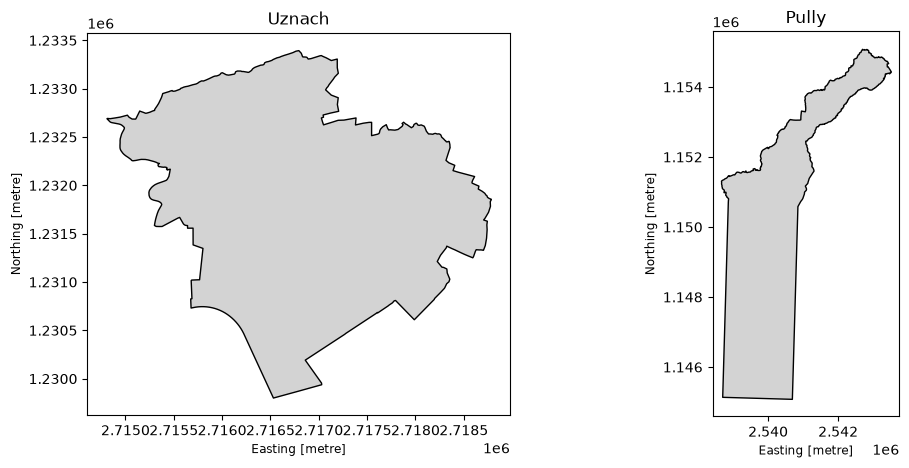

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
uznach.plot(ax=axes[0], color="lightgrey", edgecolor="black")
axes[0].set_title("Uznach")
pully.plot(ax=axes[1], color="lightgrey", edgecolor="black")
axes[1].set_title("Pully")
plt.show()

**Observation:** The outputs for Uznach and Pully are plausible. 

### 3.3 Roof surfaces (sonnendach.ch)
The file contains all roofs in Switzerland. With `mask=` we only read the roofs inside one municipality.

In [7]:
roofs_uznach = gpd.read_file("../data/raw/SOLKAT_DACH.gpkg", layer="SOLKAT_CH_DACH", mask=uznach)
roofs_pully = gpd.read_file("../data/raw/SOLKAT_DACH.gpkg", layer="SOLKAT_CH_DACH", mask=pully)

print("Uznach:", len(roofs_uznach), "roof surfaces")
print("Pully:", len(roofs_pully), "roof surfaces")

Uznach: 6183 roof surfaces
Pully: 11857 roof surfaces


In [8]:
roofs_uznach[["GWR_EGID", "KLASSE", "FLAECHE", "NEIGUNG", "STROMERTRAG"]].head()

,GWR_EGID,KLASSE,FLAECHE,NEIGUNG,STROMERTRAG
0,1730872.0,2,49.839654,39,7185
1,1730872.0,5,67.290582,41,15084
2,1730872.0,2,12.665281,35,1870
3,1730872.0,4,47.462777,38,9675
4,1730872.0,1,13.801273,46,1440


In [9]:
print(roofs_uznach["KLASSE"].value_counts().sort_index())
print(roofs_pully["KLASSE"].value_counts().sort_index())

KLASSE
1     957
2    1389
3    1774
4    1486
5     577
Name: count, dtype: int64
KLASSE
1    1692
2    1885
3    2616
4    3292
5    2372
Name: count, dtype: int64


In [10]:
roofs_uznach.to_file("../data/interim/roofs_uznach.gpkg")
roofs_pully.to_file("../data/interim/roofs_pully.gpkg")

**Observation:** _comment on output_

### 3.4 BFE register of PV plants
PV plants have `SubCategory == "subcat_2"`. The coordinates are in the columns `_x` and `_y` (LV95).

In [11]:
plants = pd.read_csv("../data/raw/ElectricityProductionPlant.csv")
print(len(plants), "plants in total")

pv = plants[plants["SubCategory"] == "subcat_2"]
print(len(pv), "PV plants")

345190 plants in total
343134 PV plants


In [12]:
pv = gpd.GeoDataFrame(pv, geometry=gpd.points_from_xy(pv["_x"], pv["_y"]), crs="EPSG:2056")

pv_uznach = gpd.clip(pv, uznach)
pv_pully = gpd.clip(pv, pully)

print("Uznach:", len(pv_uznach), "PV plants")
print("Pully:", len(pv_pully), "PV plants")

pv_uznach.to_file("../data/interim/pv_register_uznach.gpkg")
pv_pully.to_file("../data/interim/pv_register_pully.gpkg")

Uznach: 295 PV plants
Pully: 310 PV plants


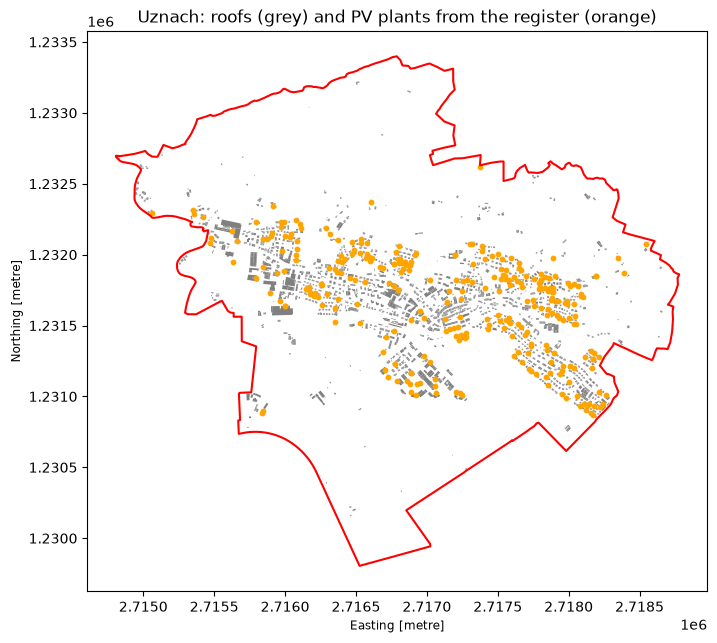

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))
uznach.boundary.plot(ax=ax, color="red")
roofs_uznach.plot(ax=ax, color="grey")
pv_uznach.plot(ax=ax, color="orange", markersize=10)
ax.set_title("Uznach: roofs (grey) and PV plants from the register (orange)")
plt.show()

**Observation:** _We can see, that most of the roofs in Uznach are concentrated along the middle of the municipality. There are a lot of PV plants there, but still potential. Bigger buildings only have one dot, but probably several pv's on their roof._

### 3.5 SWISSIMAGE aerial images
SWISSIMAGE is split into tiles of 1 x 1 km. The file name contains the flight year and the lower left corner
of the tile in km, e.g. `swissimage-dop10_2025_2716-1231_0.1_2056.tif`.
We go through all tiles around the municipality and only download the ones that contain roofs
(this skips e.g. the tiles on Lake Geneva in Pully). We use the newest flight year: 2025 for Uznach, 2023 for Pully.

In [14]:
def download_tiles(roofs, year, folder):
    os.makedirs(folder, exist_ok=True)
    roof_area = roofs.union_all()
    xmin, ymin, xmax, ymax = roofs.total_bounds

    for e in range(int(xmin // 1000), int(xmax // 1000) + 1):
        for n in range(int(ymin // 1000), int(ymax // 1000) + 1):
            tile = box(e * 1000, n * 1000, e * 1000 + 1000, n * 1000 + 1000)
            if tile.intersects(roof_area):
                name = f"swissimage-dop10_{year}_{e}-{n}"
                url = f"https://data.geo.admin.ch/ch.swisstopo.swissimage-dop10/{name}/{name}_0.1_2056.tif"
                download(url, f"{folder}/{name}.tif")

In [15]:
download_tiles(roofs_uznach, 2025, "../data/raw/swissimage_uznach")
download_tiles(roofs_pully, 2023, "../data/raw/swissimage_pully")

print(len(os.listdir("../data/raw/swissimage_uznach")), "tiles for Uznach")
print(len(os.listdir("../data/raw/swissimage_pully")), "tiles for Pully")

downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2714-1232.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2715-1230.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2715-1231.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2715-1232.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2716-1230.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2716-1231.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2716-1232.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2716-1233.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2717-1230.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2717-1231.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2717-1232.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_2717-1233.tif
downloading ../data/raw/swissimage_uznach/swissimage-dop10_2025_

swissimage-dop10_2025_2714-1232.tif
size: 10000 x 10000 | bands: 3 | resolution: (0.1, 0.1) | crs: EPSG:2056


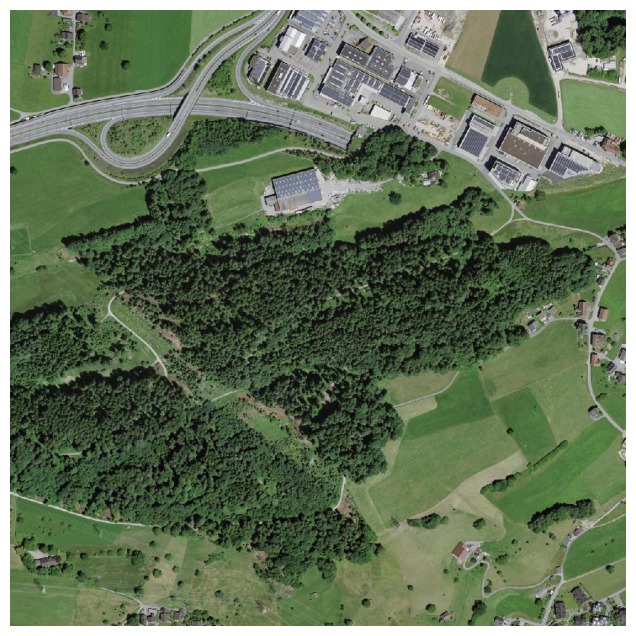

In [16]:
files = sorted(os.listdir("../data/raw/swissimage_uznach"))
src = rasterio.open("../data/raw/swissimage_uznach/" + files[0])

print(files[0])
print("size:", src.width, "x", src.height, "| bands:", src.count, "| resolution:", src.res, "| crs:", src.crs)

image = src.read(out_shape=(3, 1000, 1000))   # read smaller for plotting
plt.figure(figsize=(8, 8))
plt.imshow(image.transpose(1, 2, 0))
plt.axis("off")
plt.show()

**Observation:** _As I mentioned before, on this picture we can see, that there is indeed an industrial building with several solar panels on its roof. _

## 4. Conclusion & Open Points
